# Early Stopping in Neural Networks

> A regularization technique that halts training when the model stops improving — saving time and preventing overfitting.

---

## What Is Early Stopping?

**Early Stopping** monitors a chosen metric (usually **validation loss**) at the end of each epoch. If the metric shows no improvement for a specified number of consecutive epochs (called the **patience**), training is stopped early — before the model starts memorizing the training data.

Without early stopping, a model trained for too many epochs will overfit: it performs well on training data but poorly on unseen data.

```
Epoch 10 → val_loss: 0.45  ✅ improved
Epoch 11 → val_loss: 0.43  ✅ improved
Epoch 12 → val_loss: 0.44  ⏳ no improvement (patience: 1/3)
Epoch 13 → val_loss: 0.45  ⏳ no improvement (patience: 2/3)
Epoch 14 → val_loss: 0.46  🛑 no improvement (patience: 3/3) → STOP
```

The best model weights (from Epoch 11) are restored.

---

## Key Parameters

| Parameter | Description |
|---|---|
| `monitor` | Metric to watch — usually `val_loss` or `val_accuracy` |
| `patience` | How many epochs to wait after last improvement before stopping |
| `min_delta` | Minimum change to qualify as an improvement |
| `restore_best_weights` | If `True`, reverts model to its best checkpoint on stop |
| `mode` | `min` for loss (lower = better), `max` for accuracy (higher = better) |

---

## Uses

- **Preventing overfitting** — stops training before the model memorizes training data
- **Saving compute time** — avoids running unnecessary epochs when learning has plateaued
- **Automatic epoch tuning** — removes the need to manually guess the right number of epochs
- **Model checkpointing** — pairs naturally with saving the best weights during training
- **Hyperparameter search** — speeds up trials in grid/random search by cutting bad runs short

---

## Advantages

- Simple to implement — just a callback in most frameworks
- Acts as a regularizer without modifying model architecture
- Saves training time and compute costs
- Works with any model and any metric

## Disadvantages

- Requires a validation set — reduces the data available for training
- Too small a `patience` can stop training prematurely
- Too large a `patience` reduces its effectiveness
- May not be ideal when loss curves are naturally noisy (e.g., with small batch sizes or SGD)

---

## Key Takeaway

> Early stopping is one of the simplest yet most effective regularization tools. Set `patience` between **5–20 epochs** depending on how noisy your loss curve is, always enable `restore_best_weights`, and let the model tell you when it's done learning.

In [5]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pylab import rcParams
import matplotlib.pyplot as plt
import warnings
from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import seaborn as sns

In [6]:
X, y = make_circles(n_samples=100, noise=0.1, random_state=1)

<Axes: >

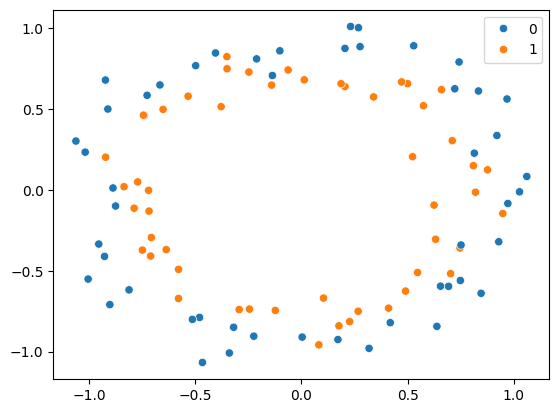

In [7]:
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2)

In [9]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [11]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, verbose=0)

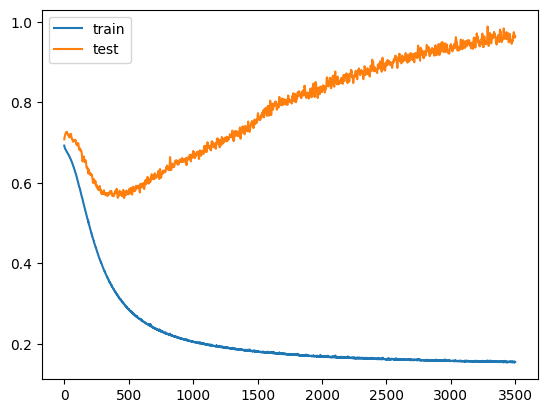

In [12]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


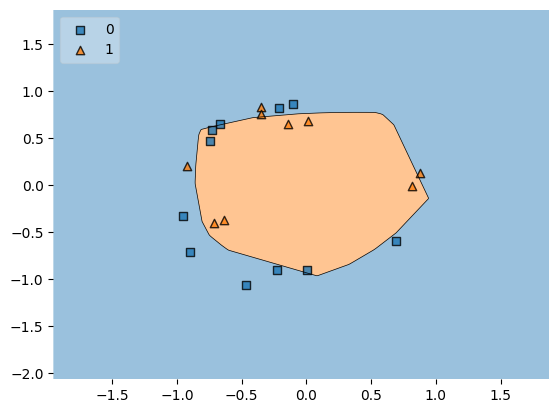

In [13]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()

# Early Stopping

In [14]:
model = Sequential()

model.add(Dense(256, input_dim=2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [15]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [16]:
callback = EarlyStopping(
    monitor="val_loss",          # Metric to monitor during training
                                  # Here: validation loss

    min_delta=0.00001,           # Minimum improvement required to count as progress
                                  # If val_loss improves by less than this, it is ignored

    patience=20,                 # Number of epochs to wait with no significant improvement
                                  # before stopping training

    verbose=1,                   # Prints messages when early stopping happens
                                  # 0 = silent, 1 = show logs

    mode="auto",                 # Automatically decides whether metric should decrease or increase
                                  # For val_loss, lower is better

    baseline=None,               # Training stops if model never beats this value
                                  # None = no baseline requirement

    restore_best_weights=False   # If True, restores weights from the best epoch
                                  # If False, keeps weights from last epoch
)

In [17]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3500, callbacks=callback)

Epoch 1/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.4750 - loss: 0.6953 - val_accuracy: 0.4000 - val_loss: 0.7078
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5250 - loss: 0.6928 - val_accuracy: 0.3500 - val_loss: 0.7100
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5500 - loss: 0.6906 - val_accuracy: 0.4000 - val_loss: 0.7120
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5375 - loss: 0.6905 - val_accuracy: 0.3000 - val_loss: 0.7139
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5375 - loss: 0.6884 - val_accuracy: 0.3000 - val_loss: 0.7152
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5500 - loss: 0.6879 - val_accuracy: 0.3000 - val_loss: 0.7157
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5500 - loss: 0.6869 - val_accuracy: 0.3000 - val_loss: 0.7152
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5375 - loss: 0.6861 - val_accuracy: 0.3000 - 

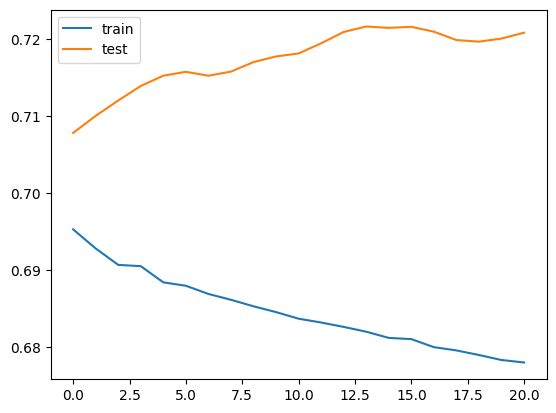

In [18]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step


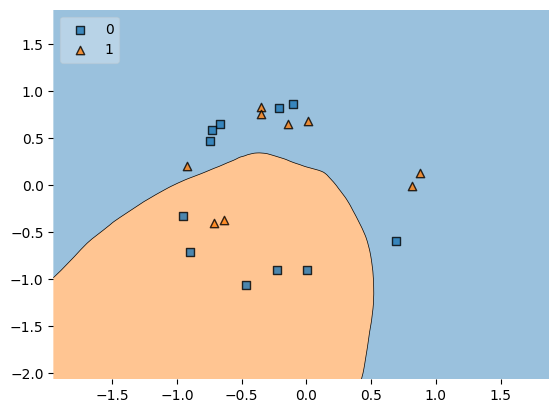

In [19]:
plot_decision_regions(X_test, y_test.ravel(), clf = model, legend=2)
plt.show()